### kurganov scheme 

In [1]:
import numpy as np 
import matplotlib.pyplot as plt

## domain construction 

In [2]:
Nx= int(input("Enter the number of cells: "))
Ny= int(input("Enter the number of cells: "))
L= float(input("Enter the length of tube: "))
H=float(input("Enter the height of tube: "))
Li=0
Hi=0
dx=(L-Li)/Nx
dy=(H-Hi)/Ny
x=np.linspace(Li+dx/2, L-dx/2, Nx)
y=np.linspace(Hi+dy/2, H-dy/2, Ny)
X,Y=np.meshgrid(x,y, indexing='ij')
gamma=1.4

### MAKING VARIABLES

In [3]:
U = np.zeros((4, Nx, Ny))

rho = np.where(X < L/2, 1.0, 0.125)
u = np.zeros((Nx, Ny))
v = np.zeros((Nx, Ny))
p = np.where(X < L/2, 1.0, 0.1)
E = p/(gamma - 1) + 0.5*rho*(u**2 + v**2)
U[0] = rho
U[1] = rho*u
U[2] = rho*v
U[3] = E

In [4]:
def Initial(U):

    rho = U[0]

    u = U[1] / rho
    v = U[2] / rho

    E = U[3]

    p = (gamma - 1) * (
        E - 0.5*rho*(u**2 + v**2)
    )

    return rho, u, v, p

In [5]:
def minmod(a, b):
    return np.where(a*b> 0, np.sign(a)*np.minimum(np.abs(a), np.abs(b)), 0.0)
def MUSCL_x(U):
    slope_x= np.zeros_like(U)
    for i in range(1, Nx-1):
        slope_x[:, i, :]= minmod(U[:, i, :]-U[:, i-1, :], U[:, i+1, :]-U[:, i, :])
    return slope_x
def MUSCL_y(U):
    slope_y= np.zeros_like(U)
    for j in range(1, Ny-1):
        slope_y[:, :, j]= minmod(U[:, :, j]-U[:, :, j-1], U[:, :, j+1]-U[:, :, j])
    return slope_y

In [6]:
def flux_x(U, gamma):

    rho = U[0]
    u   = U[1] / rho
    v   = U[2] / rho
    E   = U[3]
    p = (gamma - 1) * (
        E - 0.5*rho*(u**2 + v**2))
    F = np.zeros_like(U)
    F[0] = rho*u
    F[1] = rho*u**2 + p
    F[2] = rho*u*v
    F[3] = u*(E + p)

    return F

In [7]:
def flux_y(U, gamma):

    rho = U[0]
    u   = U[1] / rho
    v   = U[2] / rho
    E   = U[3]

    p = (gamma - 1) * (
        E - 0.5*rho*(u**2 + v**2)
    )

    G = np.zeros_like(U)

    G[0] = rho*v
    G[1] = rho*u*v
    G[2] = rho*v**2 + p
    G[3] = v*(E + p)

    return G

In [8]:

def tadmor_x(Ul, Ur, gamma=1.4):

    rhol, ul, vl, pl = Initial(Ul)
    rhor, ur, vr, pr = Initial(Ur)

    Fl = flux_x(Ul, gamma)
    Fr = flux_x(Ur, gamma)

    al = np.sqrt(gamma * pl / rhol)
    ar = np.sqrt(gamma * pr / rhor)

    Sl = np.minimum(0.0, np.minimum(ul - al, ur - ar))
    Sr = np.maximum(0.0, np.maximum(ul + al, ur + ar))

    dS = Sr - Sl
    dS_safe = np.where(dS > 1e-12, dS, 1.0)   # avoid divide-by-zero

    F_knp = (Sr * Fl - Sl * Fr) / dS_safe + (Sr * Sl / dS_safe) * (Ur - Ul)
    F_avg = 0.5 * (Fl + Fr)

    return np.where(dS > 1e-12, F_knp, F_avg)

In [9]:
def tadmor_y(Ul, Ur, gamma=1.4):

    rhol, ul, vl, pl = Initial(Ul)
    rhor, ur, vr, pr = Initial(Ur)

    Fl = flux_x(Ul, gamma)
    Fr = flux_x(Ur, gamma)

    al = np.sqrt(gamma * pl / rhol)
    ar = np.sqrt(gamma * pr / rhor)

    Sl = np.minimum(0.0, np.minimum(vl - al, vr - ar))
    Sr = np.maximum(0.0, np.maximum(vl + al, vr + ar))

    dS = Sr - Sl
    dS_safe = np.where(dS > 1e-12, dS, 1.0)   # avoid divide-by-zero

    F_knp = (Sr * Fl - Sl * Fr) / dS_safe + (Sr * Sl / dS_safe) * (Ur - Ul)
    F_avg = 0.5 * (Fl + Fr)

    return np.where(dS > 1e-12, F_knp, F_avg)

In [10]:
CFL = 0.2
t = 0.0
t_end = 0.2

while t < t_end:

    rho, u, v, p = Initial(U)
    a = np.sqrt(gamma * p / rho)

    max_speed_x = np.max(np.abs(u) + a)
    max_speed_y = np.max(np.abs(v) + a)

    dt = CFL / ((max_speed_x / dx) + (max_speed_y / dy))
    if t + dt > t_end:
        dt = t_end - t

    slope_x = MUSCL_x(U)
    slope_y = MUSCL_y(U)

    Fx_interface = np.zeros((4, Nx + 1, Ny))
    Gy_interface = np.zeros((4, Nx, Ny + 1))

    for i in range(1, Nx):
        for j in range(Ny):
            UL = U[:, i-1, j] + 0.5 * slope_x[:, i-1, j]
            UR = U[:, i, j]   - 0.5 * slope_x[:, i, j]
            Fx_interface[:, i, j] = tadmor_x(UL, UR, gamma)

    for i in range(Nx):
        for j in range(1, Ny):
            UL = U[:, i, j-1] + 0.5 * slope_y[:, i, j-1]
            UR = U[:, i, j]   - 0.5 * slope_y[:, i, j]
            Gy_interface[:, i, j] = tadmor_y(UL, UR, gamma)

    U_new = U.copy()
    for i in range(1, Nx-1):
        for j in range(1, Ny-1):
            U_new[:, i, j] = (U[:, i, j]
                              - (dt/dx) * (Fx_interface[:, i+1, j] - Fx_interface[:, i, j])
                              - (dt/dy) * (Gy_interface[:, i, j+1] - Gy_interface[:, i, j]))

    U_new[:, 0, :]  = U_new[:, 1, :]
    U_new[:, -1, :] = U_new[:, -2, :]
    U_new[:, :, 0]  = U_new[:, :, 1]
    U_new[:, :, -1] = U_new[:, :, -2]

    U = U_new
    t += dt

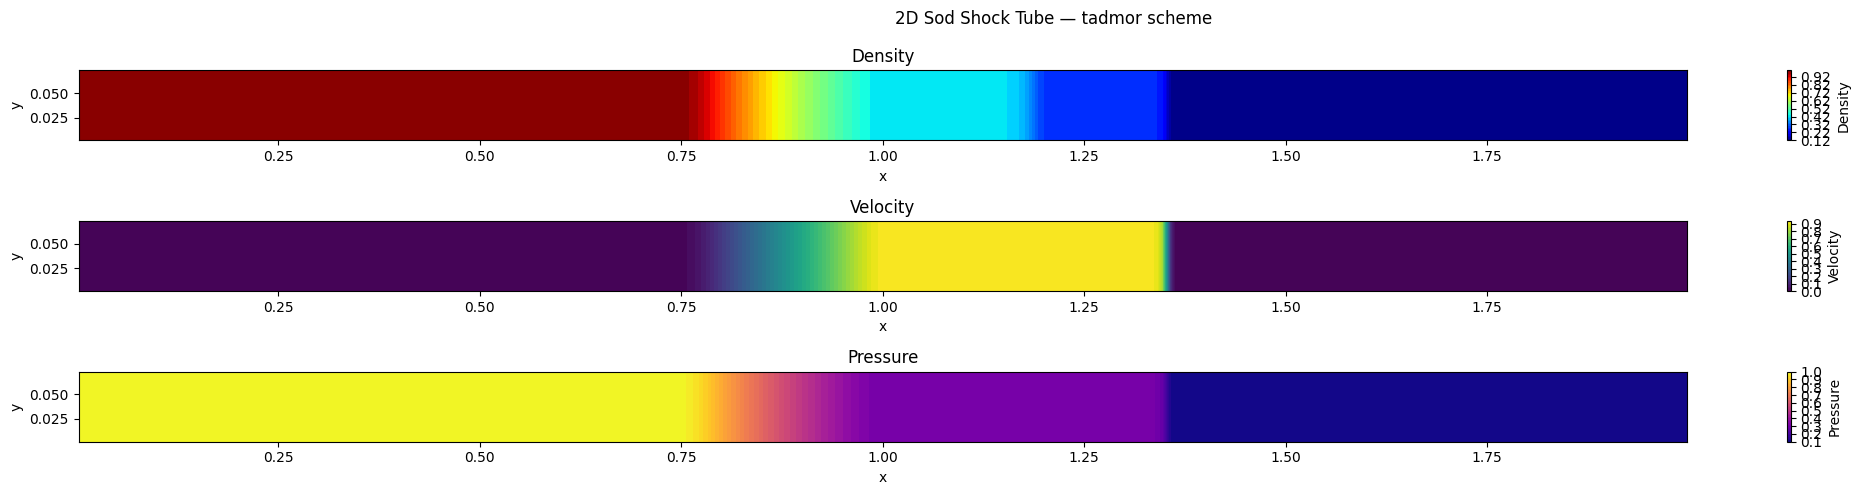

In [11]:
rho, u, v, p = Initial(U)

fig, ax = plt.subplots(3, 1, figsize=(21, 5))
# Density
c1 = ax[0].contourf(X, Y, rho, levels=50, cmap='jet')
fig.colorbar(c1, ax=ax[0], label="Density")
ax[0].set_title("Density")

# Velocity
c2 = ax[1].contourf(X, Y, u, levels=50, cmap='viridis')
fig.colorbar(c2, ax=ax[1], label="Velocity")
ax[1].set_title("Velocity")

# Pressure
c3 = ax[2].contourf(X, Y, p, levels=50, cmap='plasma')
fig.colorbar(c3, ax=ax[2], label="Pressure")
ax[2].set_title("Pressure")

for a in ax:
    a.set_xlabel("x")
    a.set_ylabel("y")

fig.suptitle("2D Sod Shock Tube — tadmor scheme")

plt.tight_layout()
plt.show()